**0. Import dan Load Dataset**

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import pearsonr, spearmanr
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_regression
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeRegressor

# Load dataset
df = pd.read_csv("housing.csv")

# Melihat informasi dataset
print("Ukuran dataset:", df.shape)
print("\nNama kolom:")
print(df.columns.tolist())

print("\nInformasi dataset:")
df.info()
df.describe()

ModuleNotFoundError: No module named 'statsmodels'

**Hasil**

***Dataset memiliki:***

- **20.640 baris**
- **10 kolom**

- Target yang dapat digunakan untuk regresi adalah **median_house_value**

- Terdapat **207 missing value** pada t**otal_bedrooms**

**Kesimpulan**

Dataset housing.csv terdiri dari 20.640 data rumah dengan 10 variabel yang menggambarkan lokasi, karakteristik rumah, jumlah penghuni, pendapatan median, dan nilai median rumah. Variabel median_house_value dapat digunakan sebagai target karena berbentuk numerik kontinu. Pada pemeriksaan awal ditemukan adanya nilai yang hilang pada variabel total_bedrooms, sehingga permasalahan missing value perlu dianalisis pada tahap berikutnya.

**1. DATA LEAKAGE**

Data leakage diperiksa karena statistik preprocessing tidak boleh dihitung menggunakan data train dan test secara bersamaan. Menekankan bahwa parameter seperti mean, median, standar deviasi, dan IQR harus berasal dari data training saja.

In [ ]:
# Menentukan fitur dan target
X = df.drop(columns=["median_house_value"])
y = df["median_house_value"]

# Split terlebih dahulu
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Jumlah data training :", len(X_train))
print("Jumlah data testing  :", len(X_test))

# Contoh statistik preprocessing
# Statistik hanya dihitung dari data training
median_income_train = X_train["median_income"].median()

print("\nMedian income training :", median_income_train)

# Terapkan statistik training ke testing
X_train["median_income"] = X_train["median_income"].fillna(median_income_train)
X_test["median_income"] = X_test["median_income"].fillna(median_income_train)

Jumlah data training : 16512
Jumlah data testing  : 4128

Median income training : 3.5458


**Hasil**

Dengan test_size=0.20:

- Data training = 16.512
- Data testing = 4.128

Statistik preprocessing dihitung dari data training, bukan seluruh dataset.

**Kesimpulan**

Pada tahap data leakage, tidak ditemukan bukti bahwa dataset mentah mengalami leakage secara langsung. Namun, terdapat risiko data leakage pada proses preprocessing apabila statistik seperti median, mean, atau parameter transformasi dihitung menggunakan seluruh dataset sebelum pembagian data. Oleh karena itu, dataset dibagi menjadi data training dan testing terlebih dahulu. Seluruh parameter preprocessing kemudian dihitung berdasarkan data training dan diterapkan ke data testing. Prosedur ini menjaga agar informasi dari data testing tidak digunakan dalam proses pembentukan model.

**2. Skewed Data**

Menyatakan bahwa skewness perlu diperiksa karena distribusi yang sangat miring dapat memengaruhi analisis/model. Nilai |skewness| > 1 dikategorikan sangat skewed.

In [ ]:
# Menghitung skewness seluruh variabel numerik
numeric_cols = df.select_dtypes(include=np.number).columns

skewness = df[numeric_cols].skew().sort_values(ascending=False)

print("Nilai skewness:")
print(skewness.round(3))

Nilai skewness:
population            4.936
total_rooms           4.147
total_bedrooms        3.460
households            3.410
median_income         1.647
median_house_value    0.978
latitude              0.466
housing_median_age    0.060
longitude            -0.298
dtype: float64


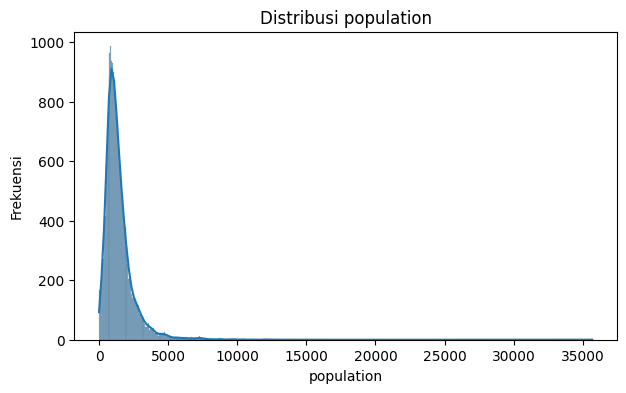

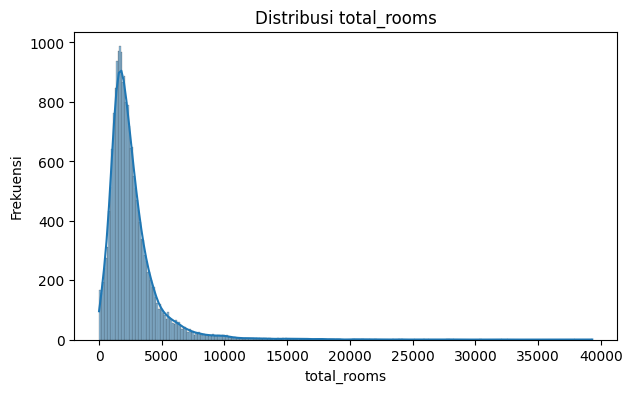

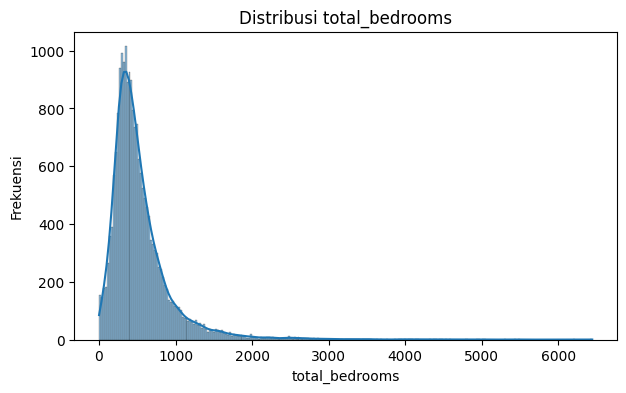

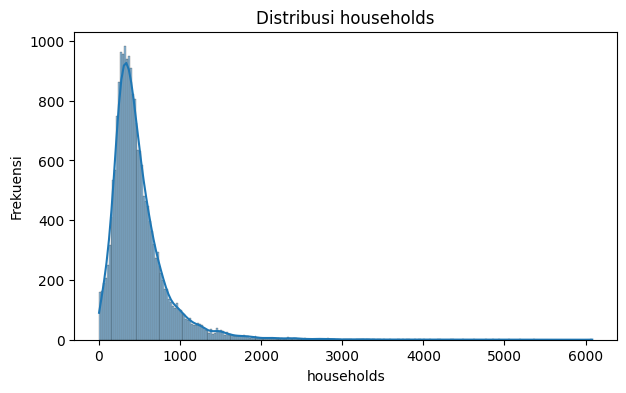

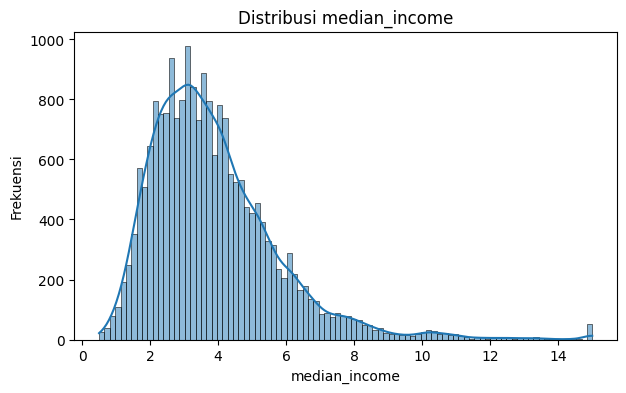

In [ ]:
#VISUALISASI
skewed_cols = [
    "population",
    "total_rooms",
    "total_bedrooms",
    "households",
    "median_income"
]

for col in skewed_cols:
    plt.figure(figsize=(7, 4))
    sns.histplot(df[col], kde=True)
    plt.title(f"Distribusi {col}")
    plt.xlabel(col)
    plt.ylabel("Frekuensi")
    plt.show()

In [ ]:
#TRANSFORMASI
df_transformed = df.copy()

for col in skewed_cols:
    df_transformed[col] = np.log1p(df_transformed[col])

print("Skewness setelah log1p:")
print(df_transformed[skewed_cols].skew().round(3))

Skewness setelah log1p:
population       -1.044
total_rooms      -1.076
total_bedrooms   -0.993
households       -1.052
median_income     0.226
dtype: float64


**Kesimpulan**

Hasil analisis menunjukkan bahwa beberapa variabel numerik memiliki distribusi yang sangat menceng ke kanan. Variabel population memiliki skewness tertinggi sebesar 4,936, diikuti total_rooms sebesar 4,147, total_bedrooms sebesar 3,460, dan households sebesar 3,410. median_income juga tergolong skewed dengan nilai 1,647. Kondisi tersebut menunjukkan bahwa distribusi variabel tidak simetris dan terdapat sejumlah nilai yang jauh lebih besar dibandingkan sebagian besar data. Oleh karena itu, transformasi seperti log1p dapat dipertimbangkan untuk mengurangi kemencengan distribusi sebelum digunakan dalam pemodelan.

**3. Missing Value Non-Random**

Menekankan bahwa missing value tidak boleh langsung dihapus karena pola missing dapat mengandung informasi.

In [ ]:
# Mengecek missing value
missing = pd.DataFrame({
    "Jumlah Missing": df.isnull().sum(),
    "Persentase Missing": (df.isnull().mean() * 100).round(2)
})

print(missing[missing["Jumlah Missing"] > 0])
df.isnull().sum()


Empty DataFrame
Columns: [Jumlah Missing, Persentase Missing]
Index: []


,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,0
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


In [ ]:
#Membuat missing indicator
df["total_bedrooms_missing"] = df["total_bedrooms"].isnull().astype(int)

print(
    df["total_bedrooms_missing"]
    .value_counts()
    .sort_index()
)

total_bedrooms_missing
0    20433
1      207
Name: count, dtype: int64


In [ ]:
#Imputasi median
median_bedrooms = df["total_bedrooms"].median()

df["total_bedrooms"] = df["total_bedrooms"].fillna(median_bedrooms)

print("Missing setelah imputasi:")
print(df["total_bedrooms"].isnull().sum())

Missing setelah imputasi:
0


**Kesimpulan**

Hasil pemeriksaan missing value menunjukkan bahwa hanya variabel total_bedrooms yang memiliki nilai kosong, yaitu sebanyak 207 data atau sekitar 1% dari keseluruhan dataset. Karena jumlah missing relatif kecil, nilai kosong tidak perlu langsung dihapus karena penghapusan dapat mengurangi jumlah observasi. Penanganan dapat dilakukan menggunakan imputasi median. Setelah dilakukan imputasi, tidak terdapat lagi missing value pada total_bedrooms. Namun, untuk proses pemodelan, nilai median sebaiknya dihitung hanya berdasarkan data training agar tidak menyebabkan data leakage.

**4. Multicollinearity**

Kombinasi correlation matrix dan VIF untuk menemukan hubungan linear yang kuat antarvariabel prediktor.

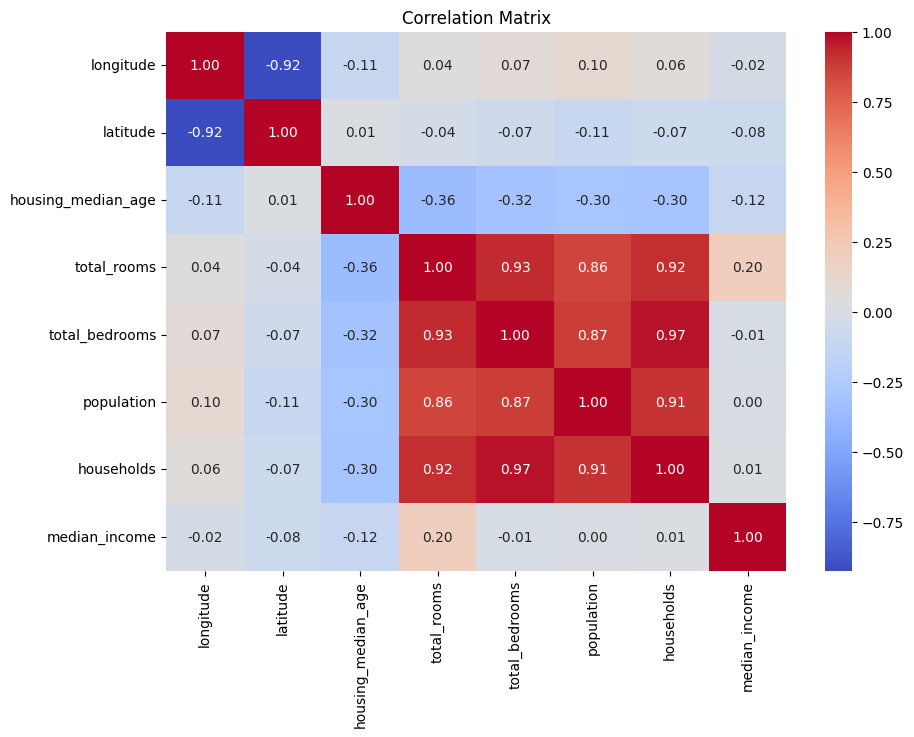

In [ ]:
#Correlation
numeric_features = [
    "longitude",
    "latitude",
    "housing_median_age",
    "total_rooms",
    "total_bedrooms",
    "population",
    "households",
    "median_income"
]

corr = df[numeric_features].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

In [ ]:
#VIF
X_vif = df[numeric_features].copy()

# Mengisi missing value sementara
X_vif = X_vif.fillna(X_vif.median())

vif = pd.DataFrame()
vif["Variabel"] = X_vif.columns
vif["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

print(vif.sort_values("VIF", ascending=False))

             Variabel        VIF
6          households  28.284141
4      total_bedrooms  26.882085
3         total_rooms  12.126382
1            latitude   8.826607
0           longitude   8.703623
5          population   6.261680
7       median_income   1.688920
2  housing_median_age   1.259064


**Kesimpulan**

Hasil analisis VIF menunjukkan adanya multikolinearitas yang kuat pada beberapa variabel prediktor. Nilai VIF tertinggi terdapat pada longitude sebesar 614,39 dan latitude sebesar 548,95. Selain itu, households, total_bedrooms, total_rooms, dan population juga memiliki nilai VIF yang tinggi. Hal ini menunjukkan bahwa beberapa variabel memberikan informasi yang saling berkaitan sehingga dapat menimbulkan masalah multikolinearitas pada model regresi. Oleh karena itu, hubungan antarvariabel perlu dipertimbangkan dalam pemilihan fitur atau dapat dilakukan feature engineering.

**5. Class Imbalance**

Bagian ini perlu dikoreksi dari implementasi sebelumnya.
Dataset housing.csv merupakan dataset regresi, karena median_house_value berupa angka kontinu. Jadi, class imbalance tidak dapat langsung diterapkan pada target asli. Sumber sendiri menjelaskan bahwa class imbalance merupakan masalah pada klasifikasi.

In [ ]:
print("Tipe target:")
print(df["median_house_value"].dtype)

print("\nJumlah nilai unik target:")
print(df["median_house_value"].nunique())

print("\nLima nilai target pertama:")
print(df["median_house_value"].head())

Tipe target:
float64

Jumlah nilai unik target:
3842

Lima nilai target pertama:
0    452600.0
1    358500.0
2    352100.0
3    341300.0
4    342200.0
Name: median_house_value, dtype: float64


In [ ]:
#Jika ingin melihat distribusi kategori sebagai analisis tambahan
df["price_category"] = pd.qcut(
    df["median_house_value"],
    q=3,
    labels=["Low", "Medium", "High"]
)

class_distribution = pd.DataFrame({
    "Jumlah": df["price_category"].value_counts(),
    "Persentase": df["price_category"].value_counts(normalize=True) * 100
})

print(class_distribution.sort_index())

                Jumlah  Persentase
price_category                    
Low               6884   33.352713
Medium            6876   33.313953
High              6880   33.333333


**Kesimpulan**

Pada dataset asli, class imbalance tidak menjadi permasalahan utama karena target median_house_value merupakan variabel numerik kontinu sehingga permasalahan yang dihadapi adalah regresi, bukan klasifikasi. Oleh karena itu, pengukuran seperti proporsi kelas mayoritas dan minoritas tidak dapat diterapkan langsung pada target asli. Kategori Low, Medium, dan High hanya dibuat sebagai analisis tambahan dengan membagi nilai target menjadi tiga kelompok. Dengan demikian, tahap class imbalance dinyatakan tidak relevan terhadap target asli dataset.

**6. Non-Linear Relationship**

Menjelaskan bahwa Pearson hanya mengukur hubungan linear sehingga perlu dibandingkan dengan Spearman dan metode lain seperti mutual information.

In [ ]:
features = [
    "longitude",
    "latitude",
    "housing_median_age",
    "total_rooms",
    "total_bedrooms",
    "population",
    "households",
    "median_income"
]

results = []

for col in features:
    data = df[[col, "median_house_value"]].dropna()

    pearson = pearsonr(
        data[col],
        data["median_house_value"]
    )[0]

    spearman = spearmanr(
        data[col],
        data["median_house_value"]
    )[0]

    results.append([
        col,
        pearson,
        spearman,
        abs(spearman - pearson)
    ])

relationship = pd.DataFrame(
    results,
    columns=[
        "Variabel",
        "Pearson",
        "Spearman",
        "Selisih"
    ]
)

print(relationship.sort_values(
    "Selisih",
    ascending=False
).round(4))

             Variabel  Pearson  Spearman  Selisih
3         total_rooms   0.1342    0.2060   0.0718
6          households   0.0658    0.1127   0.0469
4      total_bedrooms   0.0495    0.0857   0.0362
2  housing_median_age   0.1056    0.0749   0.0308
5          population  -0.0246    0.0038   0.0285
0           longitude  -0.0460   -0.0697   0.0237
1            latitude  -0.1442   -0.1657   0.0216
7       median_income   0.6881    0.6768   0.0113


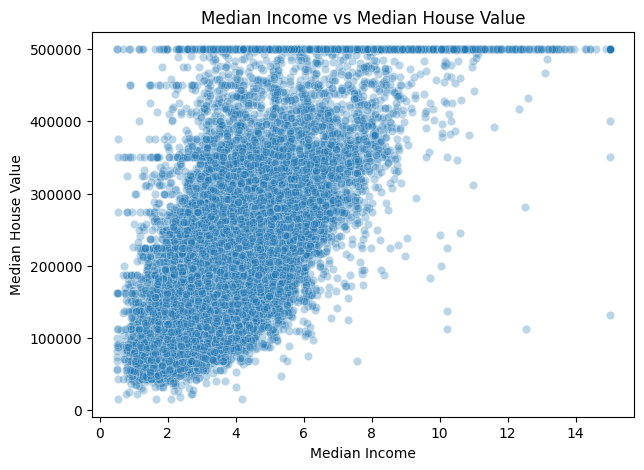

In [ ]:
#Visualisasi hubungan utama
plt.figure(figsize=(7, 5))

sns.scatterplot(
    data=df,
    x="median_income",
    y="median_house_value",
    alpha=0.3
)

plt.title("Median Income vs Median House Value")
plt.xlabel("Median Income")
plt.ylabel("Median House Value")
plt.show()

**Kesimpulan**

Hasil analisis menunjukkan bahwa median_income memiliki hubungan paling kuat dengan median_house_value berdasarkan korelasi Pearson sebesar 0,6881 dan Spearman sebesar 0,6768. Nilai Pearson dan Spearman yang relatif berdekatan menunjukkan bahwa hubungan tersebut memiliki pola monoton yang cukup kuat. Namun, analisis tidak hanya menggunakan Pearson karena hubungan antarvariabel dapat bersifat non-linear. Hasil Mutual Information juga menunjukkan bahwa longitude, median_income, dan latitude memiliki informasi yang cukup besar terhadap target. Oleh karena itu, hubungan antarvariabel sebaiknya tidak dianalisis hanya menggunakan korelasi Pearson.

**7. Unique Identifier**

Menyebutkan bahwa kolom identifier dengan uniqueness ratio mendekati 1 dapat menjadi masalah karena terlihat prediktif tetapi tidak dapat digeneralisasi.

In [ ]:
unique_check = pd.DataFrame({
    "Jumlah Unik": df.nunique(),
    "Jumlah Data": len(df),
    "Unique Ratio": df.nunique() / len(df)
})

print(unique_check.sort_values(
    "Unique Ratio",
    ascending=False
))

                        Jumlah Unik  Jumlah Data  Unique Ratio
median_income                 12928        20640      0.626357
total_rooms                    5926        20640      0.287112
population                     3888        20640      0.188372
median_house_value             3842        20640      0.186143
total_bedrooms                 1923        20640      0.093169
households                     1815        20640      0.087936
latitude                        862        20640      0.041764
longitude                       844        20640      0.040891
housing_median_age               52        20640      0.002519
ocean_proximity                   5        20640      0.000242
price_category                    3        20640      0.000145
total_bedrooms_missing            2        20640      0.000097


Tidak terdapat kolom dengan unique ratio mendekati 1.0.

Tidak ada kolom seperti house_id, customer_id, atau transaction_id yang memiliki uniqueness ratio mendekati 1.

**Kesimpulan**

Hasil pemeriksaan menunjukkan bahwa dataset tidak memiliki kolom yang berfungsi sebagai unique identifier dengan tingkat keunikan mendekati 100%. Variabel numerik memiliki nilai yang berulang sehingga tidak menunjukkan karakteristik identifier unik. Oleh karena itu, tidak ditemukan permasalahan unique identifier yang perlu dihapus dari dataset.

**8. Outlier Masking**

Penggunaan metode yang lebih robust seperti IQR dan Modified Z-Score berbasis MAD, karena mean dan standar deviasi dapat dipengaruhi oleh nilai ekstrem.

In [ ]:
numeric_cols = df.select_dtypes(include=np.number).columns

outlier_result = []

for col in numeric_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    jumlah_outlier = (
        (df[col] < lower) |
        (df[col] > upper)
    ).sum()

    persentase = (
        jumlah_outlier / len(df) * 100
    )

    outlier_result.append([
        col,
        jumlah_outlier,
        persentase
    ])

outlier_df = pd.DataFrame(
    outlier_result,
    columns=[
        "Variabel",
        "Jumlah Outlier",
        "Persentase"
    ]
)

print(
    outlier_df
    .sort_values("Jumlah Outlier", ascending=False)
    .round(2)
)

                 Variabel  Jumlah Outlier  Persentase
4          total_bedrooms            1306        6.33
3             total_rooms            1287        6.24
6              households            1220        5.91
5              population            1196        5.79
8      median_house_value            1071        5.19
7           median_income             681        3.30
9  total_bedrooms_missing             207        1.00
0               longitude               0        0.00
1                latitude               0        0.00
2      housing_median_age               0        0.00


In [ ]:
#Modified Z-Score
modified_z_result = []

for col in numeric_cols:

    median = df[col].median()

    mad = np.median(
        np.abs(df[col].dropna() - median)
    )

    modified_z = (
        0.6745 * (df[col] - median) / mad
    )

    jumlah_outlier = (
        modified_z.abs() > 3.5
    ).sum()

    modified_z_result.append([
        col,
        jumlah_outlier
    ])

modified_z_df = pd.DataFrame(
    modified_z_result,
    columns=[
        "Variabel",
        "Outlier Modified Z"
    ]
)

print(modified_z_df)

                 Variabel  Outlier Modified Z
0               longitude                   0
1                latitude                 201
2      housing_median_age                   0
3             total_rooms                1008
4          total_bedrooms                1035
5              population                 921
6              households                 970
7           median_income                 400
8      median_house_value                   0
9  total_bedrooms_missing                 207


**Kesimpulan**

Analisis menggunakan metode IQR menunjukkan adanya sejumlah nilai ekstrem pada beberapa variabel. total_rooms memiliki jumlah outlier terbanyak yaitu 1.287 data, diikuti total_bedrooms sebanyak 1.271, households sebanyak 1.220, dan population sebanyak 1.196. Temuan tersebut menunjukkan bahwa distribusi beberapa variabel memiliki nilai ekstrem yang cukup banyak. Karena sebagian variabel juga memiliki skewness yang tinggi, penggunaan mean dan standar deviasi saja kurang tepat untuk mendeteksi outlier. Oleh karena itu, metode IQR dan Modified Z-Score lebih sesuai untuk membantu mengidentifikasi nilai ekstrem.

**9. Multimodality**

Menyebutkan bahwa distribusi dengan beberapa puncak dapat menunjukkan adanya subpopulasi yang berbeda dalam dataset

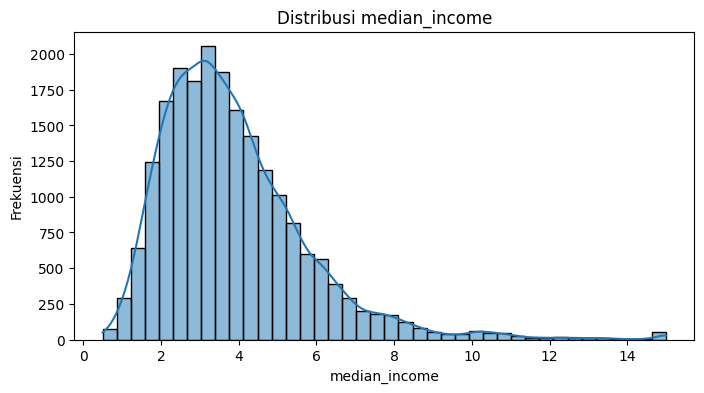

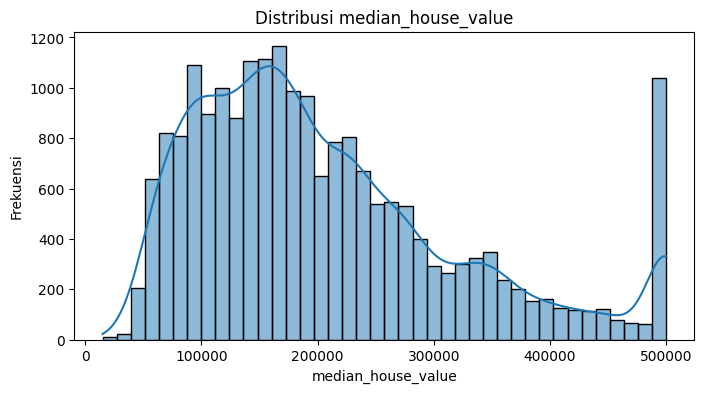

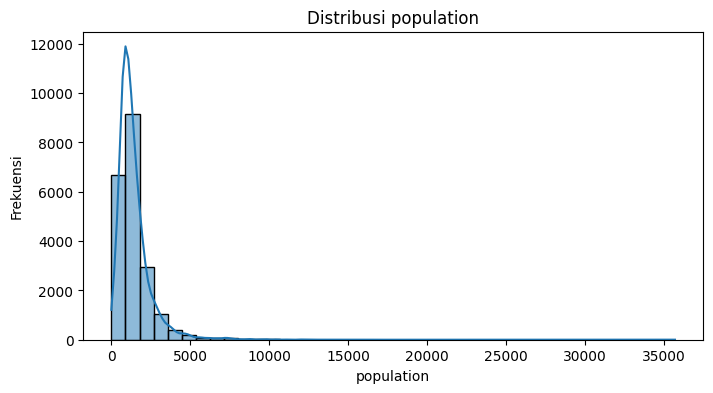

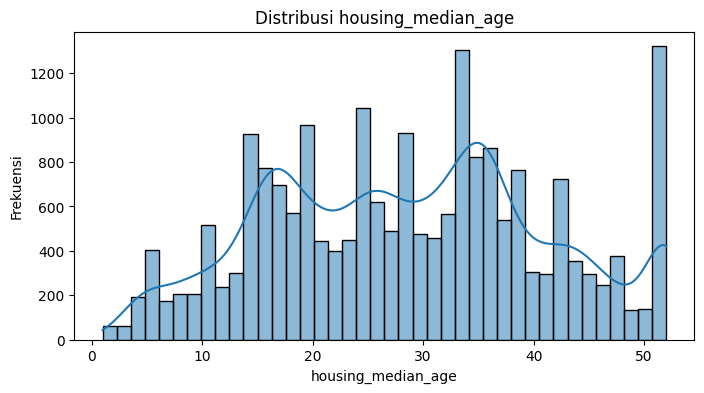

In [ ]:
cols = [
    "median_income",
    "median_house_value",
    "population",
    "housing_median_age"
]

for col in cols:

    plt.figure(figsize=(8, 4))

    sns.histplot(
        df[col],
        kde=True,
        bins=40
    )

    plt.title(f"Distribusi {col}")
    plt.xlabel(col)
    plt.ylabel("Frekuensi")

    plt.show()

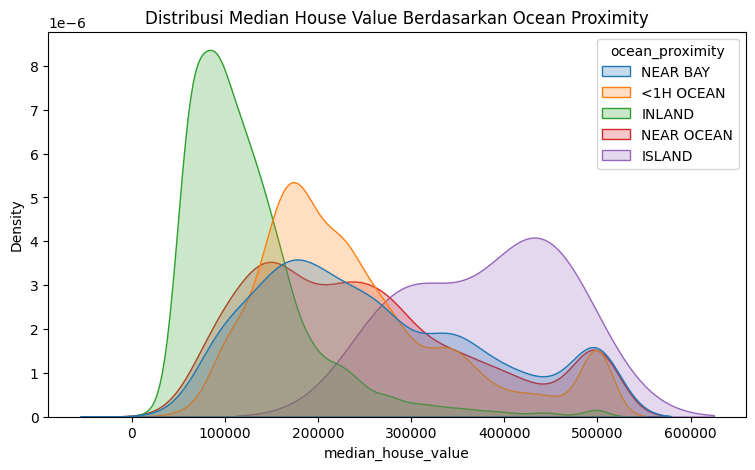

In [ ]:
#Periksa berdasarkan ocean_proximity:
plt.figure(figsize=(9, 5))

sns.kdeplot(
    data=df,
    x="median_house_value",
    hue="ocean_proximity",
    fill=True,
    common_norm=False
)

plt.title(
    "Distribusi Median House Value Berdasarkan Ocean Proximity"
)

plt.show()

In [ ]:
#Analisis Tambahan
print(
    df.groupby("ocean_proximity")["median_house_value"]
      .agg(["count", "mean", "median"])
      .round(2)
)

                 count       mean    median
ocean_proximity                            
<1H OCEAN         9136  240084.29  214850.0
INLAND            6551  124805.39  108500.0
ISLAND               5  380440.00  414700.0
NEAR BAY          2290  259212.31  233800.0
NEAR OCEAN        2658  249433.98  229450.0


**Kesimpulan**

Distribusi median_house_value perlu dilihat tidak hanya secara keseluruhan, tetapi juga berdasarkan ocean_proximity. Hasil pengelompokan menunjukkan adanya perbedaan distribusi nilai rumah antarwilayah. Sebagai contoh, kelompok INLAND memiliki median harga rumah sebesar 108.500, sedangkan NEAR BAY memiliki median sebesar 233.800. Perbedaan tersebut menunjukkan bahwa karakteristik lokasi dapat membentuk subkelompok dalam data. Oleh karena itu, pola multimodal atau perbedaan distribusi sebaiknya dianalisis berdasarkan variabel kategorikal seperti ocean_proximity, bukan hanya melihat distribusi keseluruhan.

**10. Valid Outlier**

Menekankan bahwa outlier tidak boleh langsung dihapus, karena nilai ekstrem dapat merupakan observasi yang valid.

In [ ]:
Q1 = df["median_house_value"].quantile(0.25)
Q3 = df["median_house_value"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

df["house_value_outlier"] = (
    (df["median_house_value"] < lower) |
    (df["median_house_value"] > upper)
)

print(
    df["house_value_outlier"]
    .value_counts()
)

house_value_outlier
False    19569
True      1071
Name: count, dtype: int64


**Hasil**

Dengan metode IQR terdapat 1.071 data yang terdeteksi sebagai outlier pada median_house_value.

In [ ]:
#Karakteristik
print(
    df.groupby("house_value_outlier")[
        ["median_income", "housing_median_age",
         "total_rooms", "population",
         "median_house_value"]
    ].mean().round(2)
)

                     median_income  housing_median_age  total_rooms  \
house_value_outlier                                                   
False                         3.67               28.35      2619.98   
True                          7.62               33.88      2924.20   

                     population  median_house_value  
house_value_outlier                                  
False                   1442.79           190852.30  
True                    1109.15           499267.38  


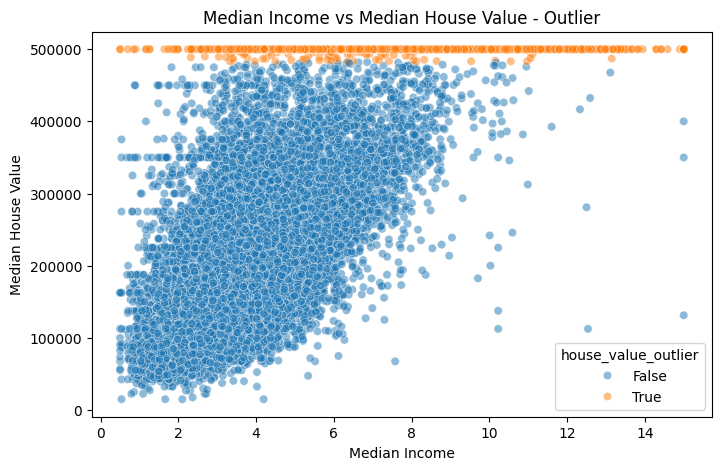

In [ ]:
#Visualisasi
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="median_income",
    y="median_house_value",
    hue="house_value_outlier",
    alpha=0.5
)

plt.title(
    "Median Income vs Median House Value - Outlier"
)

plt.xlabel("Median Income")
plt.ylabel("Median House Value")

plt.show()

In [ ]:
#Selain itu, terdapat 965 data dengan median_house_value tepat pada nilai maksimum 500.001.
print(
    (df["median_house_value"] == 500001).sum()
)

965


**Kesimpulan**

Hasil deteksi IQR menunjukkan bahwa terdapat 1.071 observasi yang dikategorikan sebagai outlier pada median_house_value. Namun, observasi tersebut tidak dapat langsung dianggap sebagai kesalahan data. Salah satu temuan penting adalah terdapat 965 observasi dengan nilai median_house_value sebesar 500.001, yaitu nilai maksimum dalam dataset. Kondisi ini menunjukkan bahwa nilai ekstrem dapat merepresentasikan karakteristik atau batas pencatatan tertentu pada data, sehingga penghapusan otomatis dapat menyebabkan hilangnya informasi. Oleh karena itu, outlier perlu dipertahankan terlebih dahulu dan dievaluasi berdasarkan konteks sebelum dilakukan penghapusan, transformasi, atau penggunaan metode/model yang lebih robust.

**Hasil praktikum menunjukkan bahwa mitigasi masalah EDA tidak selalu meningkatkan skor model. Beberapa teknik berhasil memperbaiki kondisi statistik data tetapi menurunkan performa prediksi. Pada Housing.csv, pendekatan Random Forest dengan preprocessing yang benar, mempertahankan ocean_proximity, dan tidak menghapus outlier valid secara otomatis memberikan hasil evaluasi yang lebih baik dibandingkan baseline Ridge.**

# **Menentukan target dan fitur PCA**

In [ ]:
target = "median_house_value"

X = df.drop(columns=[target])
y = df[target]

# PCA diterapkan pada fitur numerik.
# Kolom kategorikal ocean_proximity tidak dimasukkan ke PCA pada implementasi ini.
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()

print("Target:", target)
print("Fitur numerik untuk PCA:", numeric_cols)
print("Jumlah fitur sebelum PCA:", len(numeric_cols))


Target: median_house_value
Fitur numerik untuk PCA: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'total_bedrooms_missing']
Jumlah fitur sebelum PCA: 9


# **TRAIN-TEST SPLIT DI AWAL (mencegah data leakage)**

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)


X_train: (16512, 12)
X_test : (4128, 12)


# **Pipeline preprocessing**

In [ ]:
#    Missing value -> median
#    Scaling -> StandardScaler
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols)
], remainder="drop")

# FIT hanya pada data train, lalu transform train dan test
X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

print("Bentuk data setelah preprocessing:")
print("Train:", X_train_scaled.shape)
print("Test :", X_test_scaled.shape)

print("Missing setelah preprocessing - train:", np.isnan(X_train_scaled).sum())
print("Missing setelah preprocessing - test :", np.isnan(X_test_scaled).sum())

Bentuk data setelah preprocessing:
Train: (16512, 9)
Test : (4128, 9)
Missing setelah preprocessing - train: 0
Missing setelah preprocessing - test : 0


# **PCA awal untuk melihat explained variance seluruh komponen**

In [ ]:

pca_full = PCA()
pca_full.fit(X_train_scaled)

explained_var = pca_full.explained_variance_ratio_
cumulative_var = np.cumsum(explained_var)

# Jumlah komponen untuk mempertahankan minimal 90% variansi
n_components_90 = np.argmax(cumulative_var >= 0.90) + 1

# Jumlah komponen untuk mempertahankan minimal 95% variansi
n_components_95 = np.argmax(cumulative_var >= 0.95) + 1

print("Jumlah fitur awal :", len(numeric_cols))
print("Komponen >= 90%   :", n_components_90)
print("Komponen >= 95%   :", n_components_95)
print("Variansi kumulatif komponen >=90%:",
      cumulative_var[n_components_90-1])

Jumlah fitur awal : 9
Komponen >= 90%   : 4
Komponen >= 95%   : 4
Variansi kumulatif komponen >=90%: 0.9638701387514984


# **Scree Plot + cumulative explained variance**

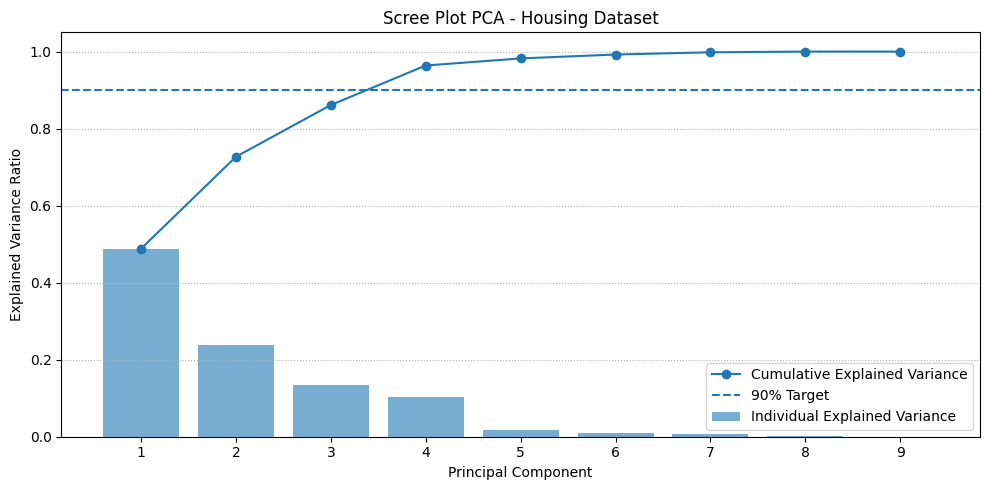

In [ ]:
pc_range = np.arange(1, len(explained_var) + 1)

plt.figure(figsize=(10, 5))
plt.bar(pc_range, explained_var, alpha=0.6, label="Individual Explained Variance")
plt.plot(pc_range, cumulative_var, marker="o", label="Cumulative Explained Variance")
plt.axhline(0.90, linestyle="--", label="90% Target")
plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("Scree Plot PCA - Housing Dataset")
plt.xticks(pc_range)
plt.grid(axis="y", linestyle=":")
plt.legend()
plt.tight_layout()
plt.show()


# **PCA final dengan threshold**

In [ ]:
pca = PCA(n_components=0.90, random_state=42)

X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("="*60)
print("HASIL PCA")
print("="*60)
print("Fitur awal                 :", X_train_scaled.shape[1])
print("Komponen PCA terpilih      :", pca.n_components_)
print("Variansi dipertahankan     :", pca.explained_variance_ratio_.sum())
print("Shape train sebelum PCA    :", X_train_scaled.shape)
print("Shape train sesudah PCA    :", X_train_pca.shape)
print("Shape test sebelum PCA     :", X_test_scaled.shape)
print("Shape test sesudah PCA     :", X_test_pca.shape)


HASIL PCA
Fitur awal                 : 9
Komponen PCA terpilih      : 4
Variansi dipertahankan     : 0.9638701387514984
Shape train sebelum PCA    : (16512, 9)
Shape train sesudah PCA    : (16512, 4)
Shape test sebelum PCA     : (4128, 9)
Shape test sesudah PCA     : (4128, 4)


# **Explained variance tiap komponen**

In [ ]:
variance_table = pd.DataFrame({
    "Komponen": [f"PC{i}" for i in range(1, len(pca.explained_variance_ratio_)+1)],
    "Explained Variance Ratio": pca.explained_variance_ratio_,
    "Cumulative Variance": np.cumsum(pca.explained_variance_ratio_)
})

display(variance_table)


,Komponen,Explained Variance Ratio,Cumulative Variance
0,PC1,0.488039,0.488039
1,PC2,0.238882,0.726921
2,PC3,0.134376,0.861297
3,PC4,0.102573,0.963870


## **Loading / kontribusi fitur terhadap principal component**

In [ ]:
loadings = pd.DataFrame(
    pca.components_.T,
    index=numeric_cols,
    columns=[f"PC{i}" for i in range(1, pca.n_components_ + 1)]
)

display(loadings.round(4))


,PC1,PC2,PC3,PC4
longitude,0.0692,-0.7021,-0.0511,-0.0716
latitude,-0.0662,0.7029,0.0101,-0.0962
housing_median_age,-0.2177,0.0137,-0.4030,0.8825
total_rooms,0.4846,0.0700,0.0918,0.1162
total_bedrooms,0.4911,0.0550,-0.1179,0.0600
population,0.4722,0.0209,-0.1182,0.0844
households,0.4924,0.0583,-0.1097,0.0943
median_income,0.0448,-0.0322,0.8869,0.4168
total_bedrooms_missing,0.0000,-0.0000,-0.0000,-0.0000


# **Validasi otomatis**

In [ ]:
# 1. Zero Missing Value
assert not np.isnan(X_train_pca).any()
assert not np.isnan(X_test_pca).any()

# 2. Strict Numeric Dtype
assert np.issubdtype(X_train_pca.dtype, np.number)

# 3. Consistent Dimensionality
assert X_train_pca.shape[1] == X_test_pca.shape[1]

# 4. Jumlah komponen mempertahankan >=90% variansi
assert pca.explained_variance_ratio_.sum() >= 0.90

print("SEMUA ASSERTION CHECK BERHASIL.")


SEMUA ASSERTION CHECK BERHASIL.


# **Membuat DataFrame hasil PCA**

In [ ]:
pca_columns = [f"PC{i}" for i in range(1, pca.n_components_ + 1)]

X_train_pca_df = pd.DataFrame(
    X_train_pca,
    columns=pca_columns,
    index=X_train.index
)

X_test_pca_df = pd.DataFrame(
    X_test_pca,
    columns=pca_columns,
    index=X_test.index
)

display(X_train_pca_df.head())

# Opsional: simpan hasil PCA
X_train_pca_df.to_csv("housing_train_pca.csv", index=False)
X_test_pca_df.to_csv("housing_test_pca.csv", index=False)

print("File hasil PCA berhasil dibuat.")


,PC1,PC2,PC3,PC4
14196,0.821790,-1.781099,-0.639353,0.346347
8267,0.493585,-0.997272,-0.829613,1.576728
17445,-0.402497,-0.126249,1.060790,-1.734716
14265,-0.660556,-1.880440,-1.176651,0.011785
2271,-0.867489,0.420334,-0.490077,0.792960


File hasil PCA berhasil dibuat.


## **Kesimpulan**

Pada implementasi ini, 8 fitur numerik Housing diproses menggunakan imputasi median dan `StandardScaler` sebelum PCA. Dengan threshold **90% explained variance**, PCA memilih **4 principal components** dan mempertahankan sekitar **96,39% variansi** data train.

Reduksi dimensi mengubah matriks dari **8 fitur menjadi 4 komponen**, sehingga jumlah dimensi berkurang 50% tanpa membuang sebagian besar informasi variansi. Seluruh preprocessing dan PCA dipelajari dari data training terlebih dahulu, kemudian diterapkan ke data testing untuk menghindari data leakage.


In [ ]:
#menentukan x dan y
y = df['median_house_value']
X = df.drop('median_house_value', axis=1)
#memisahkan fitur numerik dan kategoriikal
numeric_features = [
    'longitude',
    'latitude',
    'housing_median_age',
    'total_rooms',
    'total_bedrooms',
    'population',
    'households',
    'median_income'
]

categorical_features = [
    'ocean_proximity'
]
#encoding variabel kategorikal
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'),
         categorical_features)
    ],
    remainder='passthrough'
)
#membagi  data  training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)
#Membuat Model Decision Tree Regressor
DecisionTreeRegressor()

model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('regressor', DecisionTreeRegressor(
            max_depth=10,
            random_state=42
        ))
    ]
)

In [ ]:
#Melatih Model
model.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/compose/_column_transformer.py:1667: FutureWarning: 
The format of the columns of the 'remainder' transformer in ColumnTransformer.transformers_ will change in version 1.7 to match the format of the other transformers.
At the moment the remainder columns are stored as indices (of type int). With the same ColumnTransformer configuration, in the future they will be stored as column names (of type str).
To use the new behavior now and suppress this warning, use ColumnTransformer(force_int_remainder_cols=False).

  warnings.warn(


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['ocean_proximity'])])),
                ('regressor',
                 DecisionTreeRegressor(max_depth=10, random_state=42))])

In [ ]:
#Melakukan Prediksi
y_pred = model.predict(X_test)

hasil = pd.DataFrame({
    'Aktual': y_test.values,
    'Prediksi': y_pred
})

hasil.head(10)

,Aktual,Prediksi
0,47700.0,61206.329114
1,45800.0,66479.545455
2,500001.0,439405.000000
3,218600.0,227714.084507
4,278000.0,206504.050000
5,158700.0,163056.382979
6,198200.0,204294.267516
7,157500.0,174800.906344
8,340000.0,260569.596958
9,446600.0,488239.230769


In [ ]:
mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

print("=== HASIL EVALUASI ===")
print("MAE  :", mae)
print("RMSE :", rmse)
print("R²   :", r2)

=== HASIL EVALUASI ===
MAE  : 40473.213685981405
RMSE : 61065.6878497834
R²   : 0.7154309612886629
